[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/WOAQNN_IntrusionDetection_Kadry2023.ipynb)

# WOA-optimised quantum neural network for network intrusion detection, with elliptic-curve encryption of the model: Kadry et al. (2023) step by step

**Paper.** Heba Kadry, Ahmed Farouk, Elnomery A. Zanaty, Omar Reyad, *Intrusion detection model using optimized quantum neural network and elliptical curve cryptography for data security*, **Alexandria Engineering Journal 71 (2023) 491-500**, DOI [10.1016/j.aej.2023.03.072](https://doi.org/10.1016/j.aej.2023.03.072).

**What this notebook does.** It rebuilds the paper's pipeline on the KDD Cup 99 connection records, from scratch and on a CPU:

1. downloads the KDD Cup 99 data (10 % file), removes duplicates and builds the binary label *normal / attack* (the attack families are kept for the plots);
2. min-max normalises the features and selects them with a **Whale Optimisation Algorithm (WOA)** written in NumPy (with the crossover and mutation operators the paper adds);
3. classifies with a **quantum neural network (QNN)**, a parametrised circuit (one qubit per selected feature) simulated exactly and drawn with PennyLane, whose weights are found by WOA and then refined by gradient descent (the paper's "WOA combined with feed-forward and back-propagation");
4. compares it with the same circuit trained without WOA, and with ANN, KNN, SVM (the paper's three baselines) and a random forest on **exactly the same inputs**;
5. encrypts the trained model file with **elliptic-curve cryptography on NIST P-256**, the private key chosen by a **cuckoo search**, and checks that decryption returns the identical model;
6. ends with a per-claim comparison against the numbers the paper states.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` (a few minutes) the budgets are small; with `FAST_MODE = False` the notebook uses the paper's population and iteration counts (50 agents, 50 iterations) and more seeds (runtime is printed at the end). Everything is downloaded or generated inside the notebook.

**What you get at the end.** Plots of the real data, the executed circuit, the WOA convergence, the metric bars of the paper's Figures 4-7 redrawn from our own runs, an encrypted model file that decrypts to the same predictions, and a table that says, claim by claim, which statements of the paper we reproduced and which we did not.

## The paper in one page

- **Problem.** Network intrusion detection in wireless mesh networks with a machine-learning IDS, and secure storage of the (sensitive) model/data on a server.
- **Data.** "KDD Cup" intrusion data from the UCI repository (the paper quotes 4,898,430 records, i.e. the full KDD Cup 99 collection, 41 features per connection; reference [26] is the NSL-KDD analysis paper). Feature groups: basic (1-9), content (10-22), time-based traffic (23-31), host-based traffic (32-41).
- **Pre-processing.** Min-max normalisation, Eq. (1).
- **Feature selection.** Whale Optimisation Algorithm (circling prey, bubble-net spiral, random search; Eqs. 2-8). The population starts from random feature subsets, fitness is the quality of the classifier on a subset, the best whale guides the others, a crossover operator widens the search and a mutation operator avoids local optima. 50 search agents, 50 iterations.
- **Classifier.** A quantum neural network (quantum perceptrons, Eqs. 9-12). Every search agent encodes one candidate set of weights and biases (the paper counts `h = a*b + 2a + 1` of them for `b` inputs and `a` hidden neurons, Eq. 13), WOA searches the weights and the feed-forward / back-propagation algorithms train the network; hold-out split of train and test data.
- **Security part.** Elliptic-curve cryptography (NIST P-256) encrypts the stored file; the private key is chosen by cuckoo search (Levy flights, Eq. 14) with an entropy-based objective (Eq. 16).
- **Baselines.** ANN, KNN and SVM, compared on sensitivity, specificity, accuracy (Fig. 4), precision, recall, F-measure (Fig. 5), FPR, FNR (Fig. 6), MCC and NPV (Fig. 7).
- **Claims.** (i) The optimised QNN reaches **98.5 % accuracy** (abstract and Section 5.1); (ii) it is better than ANN, KNN and SVM on every one of those metrics; (iii) WOA feature selection helps the QNN; (iv) the cuckoo-optimised ECC gives safe storage with a small key and faster decryption than existing encryption; (v) the IDS is suitable for real-time analysis with low overhead. The paper prints **no table of numbers**: apart from the 98.5 % everything is in bar charts (Figs. 4-7) that have no values in the text.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | KDD Cup (UCI), 4,898,430 records, 41 features | KDD Cup 99 **10 % file** (494,021 records, public, `sklearn.datasets.fetch_kddcup99`), 41 features; **exact duplicates removed** (about 75 % of the file), then class-balanced samples |
| Labels | normal vs attack traffic (multiclass mentioned) | binary, attack = positive class; attack families (DoS / Probe / R2L / U2R) kept for plots and per-family recall |
| Split | "hold-out" (ratio not given) | train / validation / test samples drawn without overlap (sizes in the configuration cell); validation only for feature search; every transform fitted on the training rows only |
| Categorical features | not described | `protocol_type`, `service`, `flag` ordinal-coded (unseen -> -1); `duration`, `src_bytes`, `dst_bytes` pass through `log1p` before min-max (`# CHOICE`) |
| Normalisation | min-max, Eq. (1) | `MinMaxScaler` fitted on the training rows; test values clipped to [0, 1]; angles = pi x |
| Feature selection | WOA, 50 agents, 50 iterations, crossover + mutation, fitness from the QNN | WOA in NumPy, positions in [0,1]^41 decoded as the **top-k keys** (k = number of qubits), crossover with the best whale and mutation as in Fig. 2; **fitness = 5-NN validation error** instead of a QNN (too costly to train a QNN per fitness call, `# CHOICE`); 50 x 50 in the full run |
| Number of qubits / features | not given | `N_QUBITS = 6` (one selected feature per qubit) |
| QNN circuit | quantum perceptron, Eqs. (9)-(12); gates not specified | angle encoding `RY(pi x_i)`, `N_LAYERS` x [`RY`, `RZ` on every qubit + CNOT ring], read-out `<Z_0>`, `p(attack) = (1 - <Z_0>)/2` (`# CHOICE`; `h = ab + 2a + 1` of Eq. 13 describes a classical hidden layer and has no counterpart in a circuit, its place is taken by the 2 x layers x qubits circuit angles) |
| QNN training | WOA + feed-forward / back-propagation | WOA over the angles (binary cross-entropy on a fixed training subset, 50 x 50 in the full run) followed by Adam with parameter-shift gradients (the quantum analogue of back-propagation) |
| Baselines | ANN, KNN, SVM (settings not given) | `MLPClassifier(16)`, `KNeighborsClassifier(5)`, `SVC(rbf)`, plus `RandomForest`, all on the **same selected inputs**; RF and SVC also on all 41 features |
| ECC | NIST P-256, cuckoo search for the key, entropy objective | P-256 in pure Python (standard library), ECIES-style hybrid encryption (ECDH + SHA-256 key stream + HMAC); cuckoo search (Yang-Deb) over the 32 key bytes with a **byte-entropy + bit-balance objective** (`# CHOICE`, the paper's Eq. 16 is not reproducible as printed) |
| Metrics | sensitivity, specificity, accuracy, precision, recall, F, FPR, FNR, MCC, NPV | the same ten, from the test confusion matrix; mean +- std over seeds |
| Hardware | none (simulation) | exact noiseless state-vector simulation on the CPU; no IBM token needed |

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _need_install():
    try:
        import pennylane  # noqa: F401
        return False
    except Exception:
        return True

# Tested versions (Colab already ships numpy, pandas, scikit-learn and matplotlib).
# Installs only on Colab or when PennyLane is missing; a session restart may be needed after the install.
if IN_COLAB or _need_install():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"], check=False)

In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant)
FAST_MODE = False            # True: small budgets (class demo, a few minutes). False: the paper's 50 agents x 50 iterations, more seeds
SEED = 42                    # master seed
DATA_DIR = "data"            # the KDD Cup files are cached here
LOCAL_CSV = None             # optional path of an uploaded kddcup.data_10_percent(.gz) (no header, 42 columns) if the download fails
IBM_TOKEN = ""               # not used: exact noiseless simulation only (the paper reports no hardware run)

N_QUBITS = 6                 # CHOICE: one selected feature per qubit
N_LAYERS = 3                 # CHOICE: variational layers
FS_KNN = 5                   # CHOICE: neighbours of the cheap classifier used as WOA feature-selection fitness
CROSS_RATE, MUT_RATE = 0.5, 0.05    # CHOICE: probability of crossover with the best whale / per-gene mutation (Fig. 2 operators)
ADAM_LR = 0.08               # CHOICE: Adam step size for the gradient refinement
FAM_PER = 300                # rows per attack family in the extra per-family test set
COLORS = {"Normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "tab:purple"}

if FAST_MODE:
    SEEDS = [42, 43]
    N_TRAIN_PC, N_VAL_PC, N_TEST_PC = 500, 250, 1500       # rows per class
    FS_POP, FS_ITERS = 12, 12                              # paper: 50, 50
    W_POP, W_ITERS = 16, 20                                # WOA over the circuit angles
    ADAM_STEPS, BATCH, FIT_N = 40, 256, 400                # gradient steps, mini-batch, WOA fitness subset
    ECC_NESTS, ECC_ITERS = 15, 40
else:
    SEEDS = [42, 43, 44, 45, 46]
    N_TRAIN_PC, N_VAL_PC, N_TEST_PC = 1500, 500, 5000
    FS_POP, FS_ITERS = 50, 50                              # the paper's 50 search agents, 50 iterations
    W_POP, W_ITERS = 50, 50
    ADAM_STEPS, BATCH, FIT_N = 120, 256, 600
    ECC_NESTS, ECC_ITERS = 25, 100
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| rows per class train/val/test", N_TRAIN_PC, N_VAL_PC, N_TEST_PC,
      "| WOA feature search", FS_POP, "x", FS_ITERS, "| WOA weight search", W_POP, "x", W_ITERS, "| Adam steps", ADAM_STEPS)

FAST_MODE = False | seeds [42, 43, 44, 45, 46] | rows per class train/val/test 1500 500 5000 | WOA feature search 50 x 50 | WOA weight search 50 x 50 | Adam steps 120


In [3]:
import os, time, json, math, hmac, hashlib, secrets, warnings
from functools import reduce
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import fetch_kddcup99
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, StandardScaler
from sklearn.svm import SVC
import pennylane as qml
warnings.filterwarnings("ignore")

# Hugging Face token (only needed by gated datasets; KDD Cup 99 is public and does not use it).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__,
      "| pennylane", qml.__version__, "| python", sys.version.split()[0])

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | pennylane 0.45.1 | python 3.12.10


## 1. Data: KDD Cup 99

The KDD Cup 99 collection (from the 1998 DARPA evaluation) describes TCP/IP connections with 41 features (duration, bytes, flags, counts over a 2-second window, host-based rates, ...) and a label that is either `normal.` or one of 22 attack names. We use the standard **10 % subset** (494,021 records) that scikit-learn downloads and caches. The paper quotes the full 4.9 million records; the 10 % file contains every attack type of the full file and is what almost every IDS paper trains on, so the substitution costs no diversity but keeps the notebook runnable on a laptop.

In [4]:
os.makedirs(DATA_DIR, exist_ok=True)
KDD_COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
            "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
            "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
            "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
            "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
            "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]
t0 = time.time()
if LOCAL_CSV:
    RAW = pd.read_csv(LOCAL_CSV, header=None, names=KDD_COLS + ["labels"])
else:
    RAW = fetch_kddcup99(percent10=True, data_home=DATA_DIR, as_frame=True, download_if_missing=True).frame.copy()
for c in RAW.columns:                                    # sklearn returns bytes for the text columns
    if RAW[c].dtype == object:
        RAW[c] = RAW[c].apply(lambda v: v.decode() if isinstance(v, bytes) else v)
RAW["labels"] = RAW["labels"].astype(str).str.rstrip(".")
print("loaded in %.0f s | raw shape" % (time.time() - t0), RAW.shape)

loaded in 107 s | raw shape (494021, 42)


## 2. Cleaning and labels

- Attack names are grouped into the four standard families (DoS, Probe, R2L, U2R); `normal` stays `Normal`. The **binary label** is 0 = normal, 1 = attack (attack is the positive class, as in the paper's sensitivity/specificity definitions).
- The 10 % file is about three quarters exact duplicate rows (the same `smurf` / `neptune` connection thousands of times). Left in, they would end up in both the training and the test sample and inflate every accuracy, so we **drop exact duplicates** before sampling (the paper does not mention this; the effect is measured by the classical baselines at the end).
- The numeric columns contain no missing or infinite values (asserted below).

In [5]:
FAMILY = {"normal": "Normal"}
for fam_, names in {"DoS": "back land neptune pod smurf teardrop",
                    "Probe": "ipsweep nmap portsweep satan",
                    "R2L": "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster",
                    "U2R": "buffer_overflow loadmodule perl rootkit"}.items():
    FAMILY.update({n: fam_ for n in names.split()})
assert set(RAW["labels"]) <= set(FAMILY), sorted(set(RAW["labels"]) - set(FAMILY))
num_cols = [c for c in KDD_COLS if c not in ("protocol_type", "service", "flag")]
RAW[num_cols] = RAW[num_cols].apply(pd.to_numeric)
assert np.isfinite(RAW[num_cols].values).all(), "NaN or inf in the numeric columns"
RAW["family"] = RAW["labels"].map(FAMILY)
RAW["y"] = (RAW["labels"] != "normal").astype(int)               # 0 = normal, 1 = attack
n_raw = len(RAW)
DF = RAW.drop_duplicates().reset_index(drop=True)
print(f"records {n_raw:,} -> {len(DF):,} after dropping exact duplicates ({100*(1-len(DF)/n_raw):.1f} % removed)")
print("binary label counts after de-duplication (0 normal, 1 attack):", {int(k): int(v) for k, v in DF.y.value_counts().sort_index().items()})
print("families after de-duplication:", {k: int(v) for k, v in DF.family.value_counts().items()})

records 494,021 -> 145,586 after dropping exact duplicates (70.5 % removed)
binary label counts after de-duplication (0 normal, 1 attack): {0: 87832, 1: 57754}
families after de-duplication: {'Normal': 87832, 'DoS': 54572, 'Probe': 2131, 'R2L': 999, 'U2R': 52}


## 3. Pre-processing and WOA feature selection

For every seed, `prepare(seed)`:

1. draws disjoint class-balanced **train / validation / test** samples (and, as an extra, up to `FAM_PER` rows of every attack family that are in none of the three, for the per-family recall);
2. fits everything on the **training rows only**: ordinal codes of the three text columns, `log1p` of three heavy-tailed byte/duration columns, constant-column removal, min-max scaling to [0, 1] (Eq. 1; test values are clipped to [0, 1]);
3. runs the **WOA feature selection**. A whale is a vector of 41 numbers in [0, 1]; the features with the `N_QUBITS` largest numbers are the subset (so the subset always fits the circuit, one feature per qubit). Positions move by the WOA rules of Eqs. (2)-(8): with probability 0.5 the whale shrinks around the best whale (|A| < 1) or around a random whale (|A| >= 1), otherwise it follows the logarithmic spiral around the best. After every move the paper's two extra operators act: **crossover** with the best whale and **mutation** of single genes. Fitness is the validation error of a 5-NN classifier on the subset (`# CHOICE`, see the table above).

Two reference subsets are drawn for the ablation: the `N_QUBITS` best features by ANOVA F-score on the training rows, and a random subset.

In [6]:
CAT = ["protocol_type", "service", "flag"]
HEAVY = ["duration", "src_bytes", "dst_bytes"]            # CHOICE: log1p before min-max (Eq. 1 alone squeezes these into a spike at 0)


def woa(fitness, dim, lo, hi, pop, iters, rng, X0=None, crossover=False):
    """Whale Optimisation Algorithm (minimisation). Returns best position, best fitness, history of the best fitness."""
    X = rng.uniform(lo, hi, (pop, dim)) if X0 is None else np.array(X0, dtype=float)
    fit = np.array([fitness(x) for x in X])
    b = int(fit.argmin()); best, best_f = X[b].copy(), float(fit[b])
    hist = [best_f]
    for t in range(iters):
        a = 2.0 * (1.0 - t / iters)                             # a decreases linearly from 2 to 0
        for i in range(pop):
            A = 2 * a * rng.random() - a; C = 2 * rng.random(); p = rng.random()
            if p < 0.5:
                if abs(A) < 1:                                  # exploitation: encircle the best whale (Eqs. 2-3)
                    new = best - A * np.abs(C * best - X[i])
                else:                                           # exploration: move relative to a random whale (Eqs. 5-6)
                    r = X[rng.integers(pop)]
                    new = r - A * np.abs(C * r - X[i])
            else:                                               # bubble-net spiral (Eq. 7), b = 1
                l = rng.uniform(-1, 1)
                new = np.abs(best - X[i]) * np.exp(l) * np.cos(2 * np.pi * l) + best
            if crossover:                                       # operators of the paper's Fig. 2
                if rng.random() < CROSS_RATE:
                    new = np.where(rng.random(dim) < 0.5, best, new)
                mut = rng.random(dim) < MUT_RATE
                new = np.where(mut, rng.uniform(lo, hi, dim), new)
            X[i] = np.clip(new, lo, hi)
        fit = np.array([fitness(x) for x in X])
        b = int(fit.argmin())
        if fit[b] < best_f:
            best_f, best = float(fit[b]), X[b].copy()
        hist.append(best_f)
    return best, best_f, hist


def prepare(seed):
    rng = np.random.default_rng(seed)
    y = DF.y.values
    i0 = rng.permutation(np.where(y == 0)[0]); i1 = rng.permutation(np.where(y == 1)[0])
    a, b_ = N_TRAIN_PC, N_TRAIN_PC + N_VAL_PC
    c_ = b_ + N_TEST_PC
    tr = np.concatenate([i0[:a], i1[:a]]); va = np.concatenate([i0[a:b_], i1[a:b_]]); te = np.concatenate([i0[b_:c_], i1[b_:c_]])
    used = set(tr) | set(va) | set(te)
    fam_idx = []
    for f_ in ["DoS", "Probe", "R2L", "U2R"]:
        pool = [i for i in np.where(DF.family.values == f_)[0] if i not in used]
        fam_idx += list(rng.permutation(pool)[:FAM_PER])
    fam = np.array(fam_idx, dtype=int)
    for u, v in [(tr, va), (tr, te), (va, te)]:
        assert not (set(u) & set(v)), "overlap between splits"
    tr, va, te = rng.permutation(tr), rng.permutation(va), rng.permutation(te)
    # ---- transforms fitted on the training rows only
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(DF.loc[tr, CAT])
    def feats(ix):
        d = DF.loc[ix, KDD_COLS].copy()
        d[CAT] = enc.transform(d[CAT])
        d[HEAVY] = np.log1p(d[HEAVY].astype(float))
        return d
    Dtr = feats(tr)
    keep = [c for c in KDD_COLS if Dtr[c].nunique() > 1]
    sc = MinMaxScaler((0, 1)).fit(Dtr[keep].values)
    f01 = lambda ix: np.clip(sc.transform(feats(ix)[keep].values), 0, 1)
    out = dict(seed=seed, tr=tr, va=va, te=te, fam=fam, keep=keep, enc=enc, scaler=sc,
               Xtr=f01(tr), Xva=f01(va), Xte=f01(te), Xfam=f01(fam),
               ytr=y[tr], yva=y[va], yte=y[te], yfam=y[fam], fam_te=DF.family.values[te], fam_fam=DF.family.values[fam],
               fam_tr=DF.family.values[tr])
    # ---- WOA feature selection (fitness = validation error of a cheap classifier on the subset)
    D = len(keep); k = N_QUBITS
    cap = min(len(tr), 1000); sub = rng.permutation(len(tr))[:cap]
    Xf, yf = out["Xtr"][sub], out["ytr"][sub]
    cache = {}
    def fs_fitness(pos):
        sel = tuple(sorted(np.argsort(-pos)[:k]))
        if sel not in cache:
            clf = KNeighborsClassifier(FS_KNN).fit(Xf[:, sel], yf)
            cache[sel] = 1.0 - float((clf.predict(out["Xva"][:, sel]) == out["yva"]).mean())
        return cache[sel]
    t0 = time.time()
    pos, ferr, hist = woa(fs_fitness, D, 0.0, 1.0, FS_POP, FS_ITERS, rng, crossover=True)
    out["sel"] = np.array(sorted(np.argsort(-pos)[:k])); out["fs_hist"] = hist; out["fs_err"] = ferr; out["fs_time"] = time.time() - t0
    out["fs_evals"] = len(cache)
    sk = SelectKBest(f_classif, k=k).fit(out["Xtr"], out["ytr"])
    out["sel_anova"] = np.where(sk.get_support())[0]
    out["sel_rand"] = np.array(sorted(rng.choice(D, k, replace=False)))
    return out

PREP = {}
PREP[SEED] = prepare(SEED)
P0 = PREP[SEED]
print(f"seed {SEED}: train {len(P0['tr']):,} | validation {len(P0['va']):,} | test {len(P0['te']):,} | per-family set {len(P0['fam']):,}")
print(f"features kept after dropping constant training columns: {len(P0['keep'])} of 41")
print(f"WOA feature selection: {P0['fs_time']:.1f} s, {P0['fs_evals']} distinct subsets evaluated, best 5-NN validation error {P0['fs_err']:.4f}")
print("WOA-selected features :", [P0["keep"][i] for i in P0["sel"]])
print("ANOVA-selected features:", [P0["keep"][i] for i in P0["sel_anova"]])

seed 42: train 3,000 | validation 1,000 | test 10,000 | per-family set 946
features kept after dropping constant training columns: 36 of 41
WOA feature selection: 45.6 s, 810 distinct subsets evaluated, best 5-NN validation error 0.0070
WOA-selected features : ['service', 'src_bytes', 'wrong_fragment', 'num_compromised', 'num_access_files', 'dst_host_diff_srv_rate']
ANOVA-selected features: ['src_bytes', 'dst_bytes', 'count', 'same_srv_rate', 'dst_host_srv_count', 'dst_host_same_srv_rate']


## Dataset Exploration and Visualisation

Everything below uses the real KDD Cup 99 connection records (no generated or substituted data). First the shape, the 41 feature names and the original labels with their counts; then the real class distribution; then 2-D scatter plots in which **every point is a real connection coloured by its ground-truth family** (the multiclass labels are kept: Normal, DoS, Probe, R2L, U2R). The first scatter plot uses the PCA coordinates (fitted on the training rows only); the second uses the same coordinates scaled to [0, pi] (the range of the rotation angles), and the third the angles that the QNN really receives (two of the six WOA-selected features).

raw file shape: (494021, 44) | after de-duplication: (145586, 44)

41 original features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

original label values and counts after de-duplication ( 23 distinct):
labels
normal             87832
neptune            51820
back                 968
teardrop             918
sata

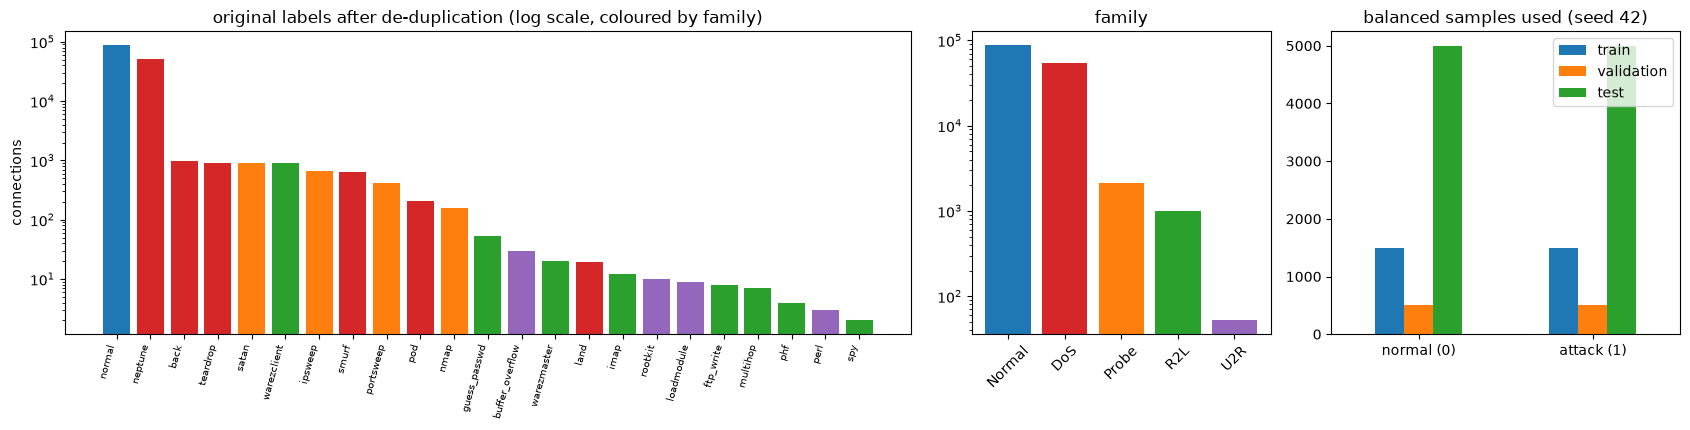

families inside the balanced TEST sample (attacks are drawn at random from the de-duplicated file, so neptune dominates): {'Normal': 5000, 'DoS': 4726, 'Probe': 196, 'R2L': 74, 'U2R': 4}


In [7]:
print("raw file shape:", RAW.shape, "| after de-duplication:", DF.shape)
print("\n41 original features:", KDD_COLS)
print("\noriginal label values and counts after de-duplication (", DF.labels.nunique(), "distinct):")
print(DF.labels.value_counts().to_string())
print("\nfamily counts:", {k: int(v) for k, v in DF.family.value_counts().items()})
print("binary label counts (0 normal, 1 attack):", {int(k): int(v) for k, v in DF.y.value_counts().sort_index().items()})
print("features kept for seed %d (constant training columns removed): %d ->" % (SEED, len(P0["keep"])), [c for c in KDD_COLS if c not in P0["keep"]], "dropped")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [3.4, 1.2, 1.4]})
vc = DF.labels.value_counts()
ax[0].bar(range(len(vc)), vc.values, color=[COLORS[FAMILY[k]] for k in vc.index])
ax[0].set_xticks(range(len(vc))); ax[0].set_xticklabels(vc.index, rotation=75, ha="right", fontsize=7)
ax[0].set_yscale("log"); ax[0].set_ylabel("connections"); ax[0].set_title("original labels after de-duplication (log scale, coloured by family)")
fc = DF.family.value_counts().reindex(["Normal", "DoS", "Probe", "R2L", "U2R"])
ax[1].bar(fc.index, fc.values, color=[COLORS[k] for k in fc.index]); ax[1].set_yscale("log"); ax[1].set_title("family"); ax[1].tick_params(axis="x", rotation=45)
bc = pd.DataFrame({"train": pd.Series(P0["ytr"]).value_counts().sort_index(), "validation": pd.Series(P0["yva"]).value_counts().sort_index(),
                   "test": pd.Series(P0["yte"]).value_counts().sort_index()})
bc.index = ["normal (0)", "attack (1)"]; bc.plot.bar(ax=ax[2], rot=0); ax[2].set_title("balanced samples used (seed %d)" % SEED)
plt.tight_layout(); plt.show()
print("families inside the balanced TEST sample (attacks are drawn at random from the de-duplicated file, so neptune dominates):",
      {k: int(v) for k, v in pd.Series(P0["fam_te"]).value_counts().items()})

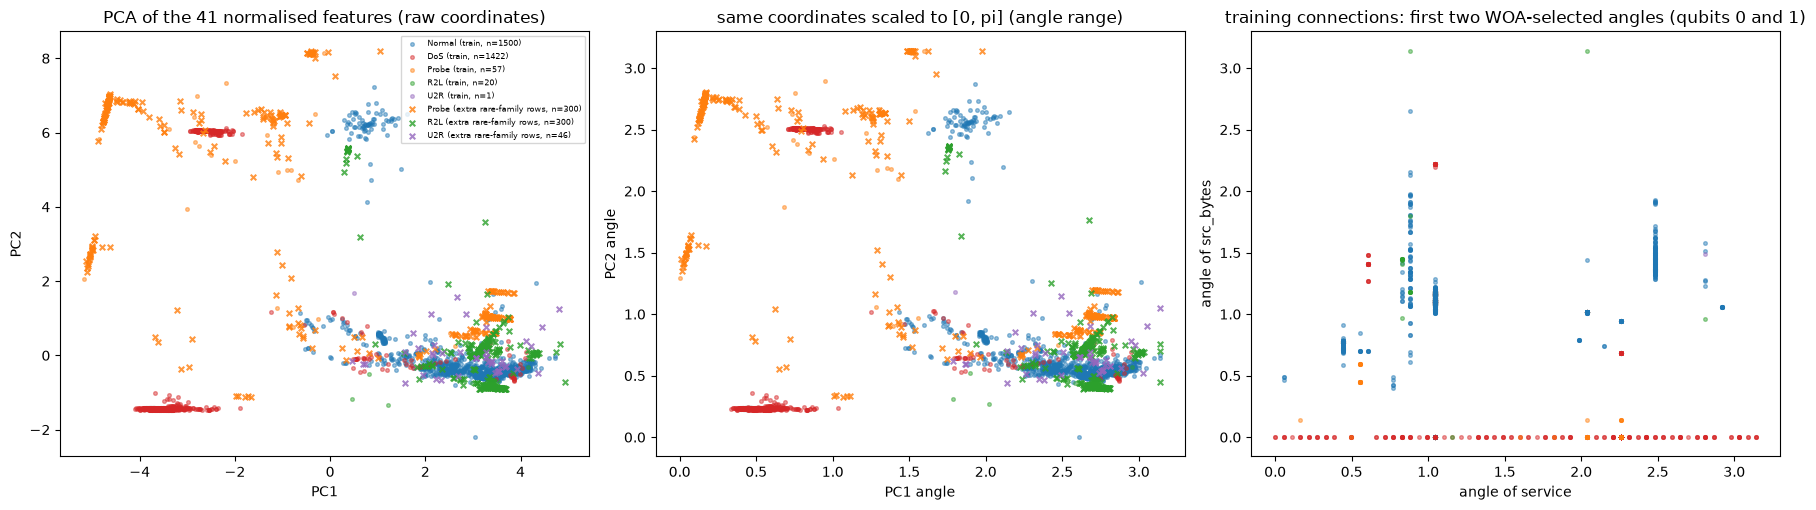

PCA explained variance (2 components): 43.4 %


In [8]:
# Raw PCA coordinates of the real connections (PCA fitted on the training rows only), then the same coordinates scaled to [0, pi]
ss = StandardScaler().fit(P0["Xtr"]); pca = PCA(n_components=2, random_state=SEED).fit(ss.transform(P0["Xtr"]))
Ztr = pca.transform(ss.transform(P0["Xtr"])); Zfam = pca.transform(ss.transform(P0["Xfam"]))
mm = MinMaxScaler((0, np.pi)).fit(Ztr)
Ztr_a, Zfam_a = np.clip(mm.transform(Ztr), 0, np.pi), np.clip(mm.transform(Zfam), 0, np.pi)
famtr = P0["fam_tr"]
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
for j, (A_, B_, ttl) in enumerate([(Ztr, Zfam, "PCA of the 41 normalised features (raw coordinates)"),
                                   (Ztr_a, Zfam_a, "same coordinates scaled to [0, pi] (angle range)")]):
    for f_ in ["Normal", "DoS", "Probe", "R2L", "U2R"]:
        m = famtr == f_
        if m.any(): ax[j].scatter(A_[m, 0], A_[m, 1], s=7, alpha=0.45, color=COLORS[f_], label=f"{f_} (train, n={m.sum()})")
    for f_ in ["Probe", "R2L", "U2R"]:
        m = P0["fam_fam"] == f_
        ax[j].scatter(B_[m, 0], B_[m, 1], s=16, marker="x", color=COLORS[f_], alpha=0.8, label=f"{f_} (extra rare-family rows, n={m.sum()})")
    ax[j].set_title(ttl); ax[j].set_xlabel("PC1" if j == 0 else "PC1 angle"); ax[j].set_ylabel("PC2" if j == 0 else "PC2 angle")
ax[0].legend(fontsize=6, loc="best")
# the angles the QNN really sees: two of the WOA-selected features
sel = P0["sel"]; ang = np.pi * P0["Xtr"][:, sel]
for f_ in ["Normal", "DoS", "Probe", "R2L", "U2R"]:
    m = famtr == f_
    if m.any(): ax[2].scatter(ang[m, 0], ang[m, 1], s=7, alpha=0.45, color=COLORS[f_])
ax[2].set_xlabel(f"angle of {P0['keep'][sel[0]]}"); ax[2].set_ylabel(f"angle of {P0['keep'][sel[1]]}")
ax[2].set_title("training connections: first two WOA-selected angles (qubits 0 and 1)")
plt.tight_layout(); plt.show()
print("PCA explained variance (2 components): %.1f %%" % (100 * pca.explained_variance_ratio_.sum()))

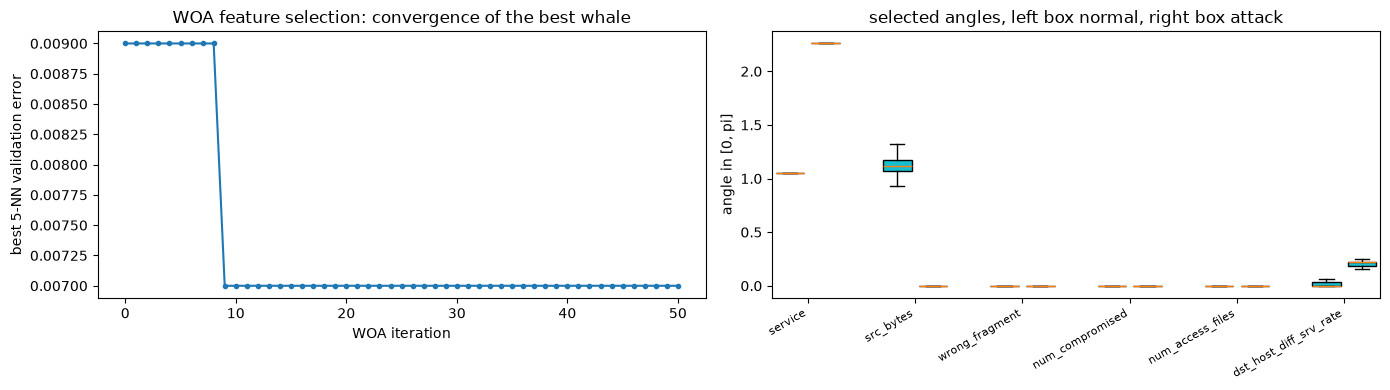

In [9]:
# WOA feature-selection convergence (seed %d) and the distribution of the six selected angles per class
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(P0["fs_hist"], marker="o", ms=3); ax[0].set_xlabel("WOA iteration"); ax[0].set_ylabel("best 5-NN validation error")
ax[0].set_title("WOA feature selection: convergence of the best whale")
for q, ix in enumerate(P0["sel"]):
    ax[1].boxplot([np.pi * P0["Xtr"][P0["ytr"] == c, ix] for c in (0, 1)], positions=[3 * q, 3 * q + 1], widths=0.8,
                  patch_artist=True, boxprops=dict(facecolor="tab:blue" if q % 2 == 0 else "tab:cyan"), showfliers=False)
ax[1].set_xticks([3 * q + 0.5 for q in range(len(P0["sel"]))]); ax[1].set_xticklabels([P0["keep"][i] for i in P0["sel"]], rotation=30, ha="right", fontsize=8)
ax[1].set_ylabel("angle in [0, pi]"); ax[1].set_title("selected angles, left box normal, right box attack")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper describes its QNN through quantum perceptrons (Eqs. 9-12) and gives no gate list, so the circuit is a `# CHOICE`:

1. **Encoding.** Qubit `i` starts in |0> and receives `RY(angle_i)` with `angle_i = pi x_i` (the selected, min-max normalised feature `x_i`).
2. **Variational layers** (`N_LAYERS`, each with fresh angles): on every qubit `RY(theta)` then `RZ(phi)`, followed by a ring of CNOTs `0->1, 1->2, ..., (n-1)->0`.
3. **Read-out.** The expectation value `<Z_0>` of qubit 0; the attack probability is `p = (1 - <Z_0>)/2` and a connection is flagged as an attack when `p > 0.5`.

The drawing below is the PennyLane QNode (`default.qubit`), i.e. the circuit that defines the model. For speed all training uses an **exact NumPy state-vector simulator** of the same gate list (the whole layer stack is multiplied into one 2^n x 2^n unitary, which makes a forward pass for hundreds of connections almost free); the cell after the drawing **asserts that this simulator equals the PennyLane QNode** on random inputs and weights, and checks the parameter-shift gradient against finite differences.

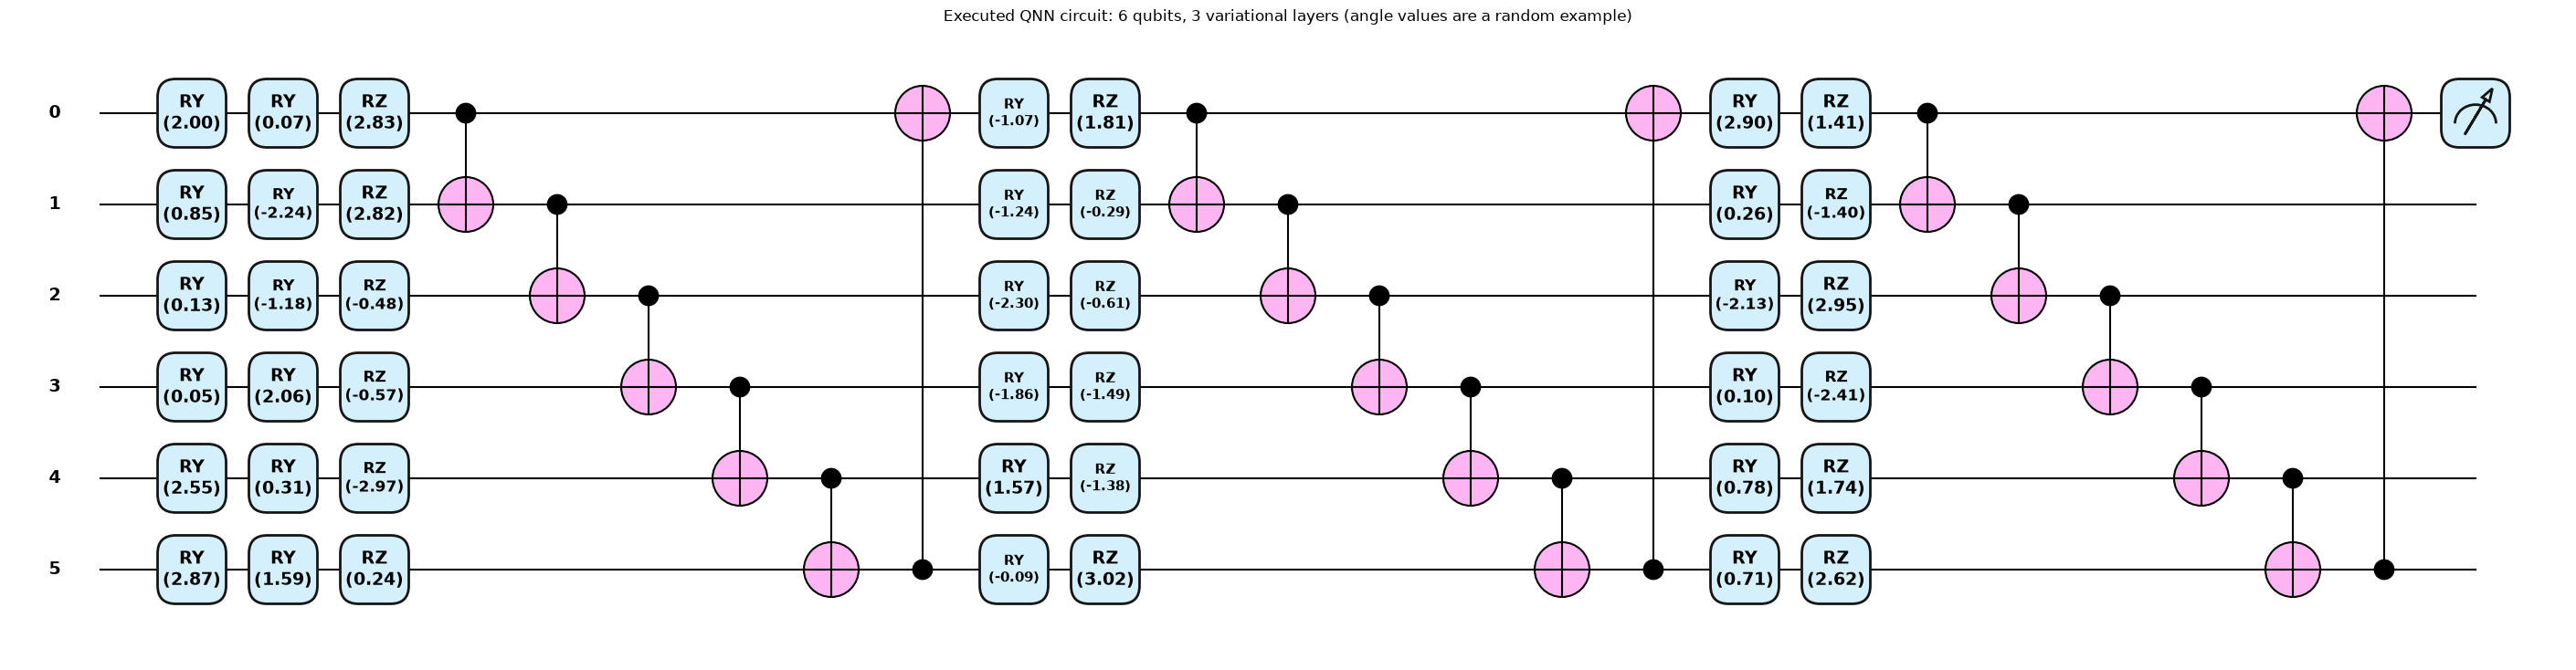

qubits: 6 | circuit depth: 25 | gates: 60 | trainable parameters: 36 (3 layers x 6 qubits x 2 rotations) | encoding angles per sample: 6
measurement: <Z_0>  ->  p(attack) = (1 - <Z_0>) / 2


In [10]:
n, L = N_QUBITS, N_LAYERS
dev = qml.device("default.qubit", wires=n)

@qml.qnode(dev)
def qnn_circuit(x, w):
    for i in range(n):                                  # encoding: one feature angle per qubit
        qml.RY(x[i], wires=i)
    for l in range(L):                                  # trainable layers
        for i in range(n):
            qml.RY(w[l, i, 0], wires=i)
            qml.RZ(w[l, i, 1], wires=i)
        for i in range(n):                              # entangling ring
            qml.CNOT(wires=[i, (i + 1) % n])
    return qml.expval(qml.PauliZ(0))                    # read-out

x_demo = np.pi * np.random.default_rng(0).random(n)
w_demo = np.random.default_rng(1).uniform(-np.pi, np.pi, (L, n, 2))
fig, ax_ = qml.draw_mpl(qnn_circuit, decimals=2, style="pennylane")(x_demo, w_demo)
fig.suptitle(f"Executed QNN circuit: {n} qubits, {L} variational layers (angle values are a random example)", y=1.02)
plt.show()
sp = qml.specs(qnn_circuit)(x_demo, w_demo)
n_params = L * n * 2
print("qubits:", n, "| circuit depth:", sp.resources.depth, "| gates:", sp.resources.num_gates,
      "| trainable parameters:", n_params, f"({L} layers x {n} qubits x 2 rotations) | encoding angles per sample: {n}")
print("measurement: <Z_0>  ->  p(attack) = (1 - <Z_0>) / 2")

In [11]:
# ---- exact NumPy simulator of the same gate list (used for training) -------------------------------------------
DIM = 2 ** n
def _ry(t): c, s = np.cos(t / 2), np.sin(t / 2); return np.array([[c, -s], [s, c]], dtype=complex)
def _rz(t): return np.array([[np.exp(-0.5j * t), 0], [0, np.exp(0.5j * t)]])
def _cnot_perm(c, t):
    b = np.arange(DIM); cb = (b >> (n - 1 - c)) & 1
    return np.where(cb == 1, b ^ (1 << (n - 1 - t)), b)
RING = np.arange(DIM)
for i in range(n):
    RING = RING[_cnot_perm(i, (i + 1) % n)]              # composed permutation of the CNOT ring
ZVEC = 1.0 - 2.0 * ((np.arange(DIM) >> (n - 1)) & 1)     # eigenvalues of Z on qubit 0 (qubit 0 = most significant bit)

def unitary(w):
    U = np.eye(DIM, dtype=complex)
    for l in range(L):
        rot = reduce(np.kron, [_rz(w[l, i, 1]) @ _ry(w[l, i, 0]) for i in range(n)])
        U = rot[RING, :] @ U                              # rotations first, then the CNOT ring
    return U

def encode(X):                                           # RY(x_i)|0> on every qubit, wire 0 = most significant
    psi = np.ones((len(X), 1))
    for i in range(n):
        q = np.stack([np.cos(X[:, i] / 2), np.sin(X[:, i] / 2)], 1)
        psi = (psi[:, :, None] * q[:, None, :]).reshape(len(X), -1)
    return psi

def expval_z0(psi, w):
    out = psi @ unitary(w).T
    return (out.real ** 2 + out.imag ** 2) @ ZVEC

def predict_p(X, w, chunk=4000):
    return np.concatenate([(1 - expval_z0(encode(X[i:i + chunk]), w)) / 2 for i in range(0, len(X), chunk)])

# ---- equivalence with the PennyLane QNode ----------------------------------------------------------------------
rg = np.random.default_rng(123); worst = 0.0
for _ in range(25):
    xx = np.pi * rg.random(n); ww = rg.uniform(-np.pi, np.pi, (L, n, 2))
    worst = max(worst, abs(float(qnn_circuit(xx, ww)) - float(expval_z0(encode(xx[None]), ww)[0])))
assert worst < 1e-10, worst
print(f"NumPy simulator == PennyLane QNode on 25 random (input, weights) pairs, max |difference| = {worst:.2e}")

# ---- loss and parameter-shift gradient --------------------------------------------------------------------------
def bce(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def loss_grad(w, psi, y):
    e0 = expval_z0(psi, w); p = np.clip((1 - e0) / 2, 1e-6, 1 - 1e-6)
    dL_dE = 0.5 * (y / p - (1 - y) / (1 - p)) / len(y)       # dBCE/dE, E = <Z_0>
    g = np.zeros(w.size)
    for j in range(w.size):                                    # parameter-shift rule: each angle sits in exactly one rotation gate
        wp, wm = w.copy().ravel(), w.copy().ravel()
        wp[j] += np.pi / 2; wm[j] -= np.pi / 2
        dE = (expval_z0(psi, wp.reshape(w.shape)) - expval_z0(psi, wm.reshape(w.shape))) / 2
        g[j] = float(np.sum(dL_dE * dE))
    return bce(p, y), g.reshape(w.shape)

rg = np.random.default_rng(7); xs = np.pi * rg.random((16, n)); ys = rg.integers(0, 2, 16).astype(float); ww = rg.uniform(-np.pi, np.pi, (L, n, 2))
_, g_ps = loss_grad(ww, encode(xs), ys)
g_fd = np.zeros(ww.size)
for j in range(ww.size):
    a_, b_ = ww.copy().ravel(), ww.copy().ravel(); a_[j] += 1e-6; b_[j] -= 1e-6
    g_fd[j] = (bce((1 - expval_z0(encode(xs), a_.reshape(ww.shape))) / 2, ys) - bce((1 - expval_z0(encode(xs), b_.reshape(ww.shape))) / 2, ys)) / 2e-6
assert np.allclose(g_ps.ravel(), g_fd, atol=1e-6), np.abs(g_ps.ravel() - g_fd).max()
print(f"parameter-shift gradient == finite differences, max |difference| = {np.abs(g_ps.ravel() - g_fd).max():.2e}")

NumPy simulator == PennyLane QNode on 25 random (input, weights) pairs, max |difference| = 5.00e-16


parameter-shift gradient == finite differences, max |difference| = 1.11e-10


## 4. The optimised QNN: WOA over the circuit angles, then gradient refinement

Three versions of the same circuit are trained on the same six angles per connection, so any difference comes from the training procedure only:

| Model | Training |
|---|---|
| **QNN, Adam only** | random initial angles, `ADAM_STEPS` Adam steps with parameter-shift gradients on mini-batches (the gradient route, "back-propagation") |
| **QNN, WOA only** | the WOA of Section 3 searches the `L*n*2` angles in [-pi, pi]; fitness = binary cross-entropy on a fixed training subset (no gradients) |
| **WOA-QNN (the paper's model)** | the WOA solution is the starting point of the same Adam steps (feed-forward + back-propagation after WOA) |

The classical baselines get the identical six inputs. For the ablation of the feature selection we also run the WOA-QNN on the six ANOVA-selected features.

In [12]:
def adam_train(w0, Xa, y, steps, rng):
    w = w0.copy(); m = np.zeros_like(w); v = np.zeros_like(w); trace = []
    for t in range(1, steps + 1):
        ix = rng.choice(len(y), min(BATCH, len(y)), replace=False)
        l, g = loss_grad(w, encode(Xa[ix]), y[ix].astype(float))
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
        w = w - ADAM_LR * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        trace.append(l)
    return w, trace

def woa_weights(Xa, y, rng):
    fi = rng.choice(len(y), min(FIT_N, len(y)), replace=False); psi = encode(Xa[fi]); yy = y[fi].astype(float)
    fit = lambda pos: bce((1 - expval_z0(psi, pos.reshape(L, n, 2))) / 2, yy)
    best, f, hist = woa(fit, L * n * 2, -np.pi, np.pi, W_POP, W_ITERS, rng, crossover=False)
    return best.reshape(L, n, 2), hist

def metrics(y, yhat, score=None):
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    dv = lambda a, b: a / b if b else 0.0
    sens, spec, prec = dv(tp, tp + fn), dv(tn, tn + fp), dv(tp, tp + fp)
    mcc = dv(tp * tn - fp * fn, math.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    r = dict(accuracy=100 * dv(tp + tn, tp + tn + fp + fn), sensitivity=100 * sens, specificity=100 * spec, precision=100 * prec,
             recall=100 * sens, f1=100 * dv(2 * tp, 2 * tp + fp + fn), fpr=100 * dv(fp, tn + fp), fnr=100 * dv(fn, tp + fn),
             mcc=mcc, npv=100 * dv(tn, tn + fn), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    r["auc"] = float(roc_auc_score(y, score)) if score is not None else np.nan
    return r

ROWS, FAMROWS, TRACE = [], [], {}
def record(seed, model, feats_name, P, sel, score_te, yhat_te, t_train, extra_pred_fam=None):
    r = metrics(P["yte"], yhat_te, score_te); r.update(seed=seed, model=model, features=feats_name, train_s=t_train)
    ROWS.append(r)
    if extra_pred_fam is not None:
        for f_ in ["DoS", "Probe", "R2L", "U2R"]:
            m = P["fam_fam"] == f_
            FAMROWS.append(dict(seed=seed, model=model, features=feats_name, family=f_, n=int(m.sum()), recall=100 * float(extra_pred_fam[m].mean())))

def run_seed(seed):
    P = PREP.get(seed) or prepare(seed); PREP[seed] = P
    rng = np.random.default_rng(seed + 1000)
    log = [f"seed {seed}"]
    sets = {"WOA": P["sel"], "ANOVA": P["sel_anova"], "random": P["sel_rand"]}
    # ---- classical baselines on identical inputs (angles = pi x on the selected features)
    for fname, sel in sets.items():
        Atr, Ate, Afam = np.pi * P["Xtr"][:, sel], np.clip(np.pi * P["Xte"][:, sel], 0, np.pi), np.clip(np.pi * P["Xfam"][:, sel], 0, np.pi)
        models = {"ANN (MLP 16)": MLPClassifier((16,), max_iter=400, random_state=seed),
                  "KNN (k=5)": KNeighborsClassifier(5),
                  "SVM (rbf)": SVC(probability=False, random_state=seed),
                  "Random forest": RandomForestClassifier(100, random_state=seed, n_jobs=1)}
        for mname, clf in models.items():
            t0 = time.time(); clf.fit(Atr, P["ytr"]); tt = time.time() - t0
            sc = clf.decision_function(Ate) if mname == "SVM (rbf)" else clf.predict_proba(Ate)[:, 1]
            record(seed, mname, fname, P, sel, sc, clf.predict(Ate), tt, extra_pred_fam=clf.predict(Afam) == 1)
    full = {"SVM (rbf), all features": SVC(random_state=seed), "Random forest, all features": RandomForestClassifier(100, random_state=seed, n_jobs=1)}
    for mname, clf in full.items():
        t0 = time.time(); clf.fit(P["Xtr"], P["ytr"]); tt = time.time() - t0
        sc = clf.decision_function(P["Xte"]) if "SVM" in mname else clf.predict_proba(P["Xte"])[:, 1]
        record(seed, mname, "all 41", P, None, sc, clf.predict(P["Xte"]), tt, extra_pred_fam=clf.predict(P["Xfam"]) == 1)
    # ---- the three QNN variants on the WOA-selected angles
    for fname in ["WOA", "ANOVA"]:
        sel = sets[fname]
        Atr, Ate, Afam = np.pi * P["Xtr"][:, sel], np.clip(np.pi * P["Xte"][:, sel], 0, np.pi), np.clip(np.pi * P["Xfam"][:, sel], 0, np.pi)
        variants = ["WOA-QNN (WOA + Adam)"] + (["QNN, Adam only", "QNN, WOA only"] if fname == "WOA" else [])
        for vname in variants:
            t0 = time.time(); tr_ = {}
            if vname == "QNN, Adam only":
                w0 = rng.uniform(-np.pi, np.pi, (L, n, 2)); w, tr_["adam"] = adam_train(w0, Atr, P["ytr"], ADAM_STEPS, rng)
            elif vname == "QNN, WOA only":
                w, tr_["woa"] = woa_weights(Atr, P["ytr"], rng)
            else:
                w0, tr_["woa"] = woa_weights(Atr, P["ytr"], rng); w, tr_["adam"] = adam_train(w0, Atr, P["ytr"], ADAM_STEPS, rng)
            tt = time.time() - t0
            pte = predict_p(Ate, w); pfam = predict_p(Afam, w)
            record(seed, vname, fname, P, sel, pte, (pte > 0.5).astype(int), tt, extra_pred_fam=pfam > 0.5)
            TRACE[(seed, vname, fname)] = dict(w=w, **tr_)
            log.append(f"  {vname:24s} [{fname:5s}] test acc {ROWS[-1]['accuracy']:.2f} %  ({tt:.0f} s)")
    print("\n".join(log), flush=True)

T_ALL = time.time()
for s_ in SEEDS:
    run_seed(s_)
print(f"all seeds done in {(time.time() - T_ALL) / 60:.1f} min")
RES = pd.DataFrame(ROWS); FAMRES = pd.DataFrame(FAMROWS)

seed 42
  WOA-QNN (WOA + Adam)     [WOA  ] test acc 87.31 %  (129 s)
  QNN, Adam only           [WOA  ] test acc 90.25 %  (129 s)
  QNN, WOA only            [WOA  ] test acc 81.67 %  (47 s)
  WOA-QNN (WOA + Adam)     [ANOVA] test acc 93.51 %  (257 s)


seed 43
  WOA-QNN (WOA + Adam)     [WOA  ] test acc 91.45 %  (315 s)
  QNN, Adam only           [WOA  ] test acc 93.47 %  (187 s)
  QNN, WOA only            [WOA  ] test acc 92.03 %  (62 s)
  WOA-QNN (WOA + Adam)     [ANOVA] test acc 93.93 %  (197 s)


seed 44
  WOA-QNN (WOA + Adam)     [WOA  ] test acc 95.93 %  (280 s)
  QNN, Adam only           [WOA  ] test acc 95.75 %  (236 s)
  QNN, WOA only            [WOA  ] test acc 85.92 %  (59 s)
  WOA-QNN (WOA + Adam)     [ANOVA] test acc 95.45 %  (248 s)


seed 45
  WOA-QNN (WOA + Adam)     [WOA  ] test acc 89.63 %  (107 s)
  QNN, Adam only           [WOA  ] test acc 95.73 %  (55 s)
  QNN, WOA only            [WOA  ] test acc 69.77 %  (17 s)
  WOA-QNN (WOA + Adam)     [ANOVA] test acc 95.14 %  (61 s)


seed 46
  WOA-QNN (WOA + Adam)     [WOA  ] test acc 90.62 %  (35 s)
  QNN, Adam only           [WOA  ] test acc 92.60 %  (24 s)
  QNN, WOA only            [WOA  ] test acc 94.76 %  (11 s)
  WOA-QNN (WOA + Adam)     [ANOVA] test acc 93.77 %  (31 s)


all seeds done in 50.0 min


### 4.1 Training curves of seed 42

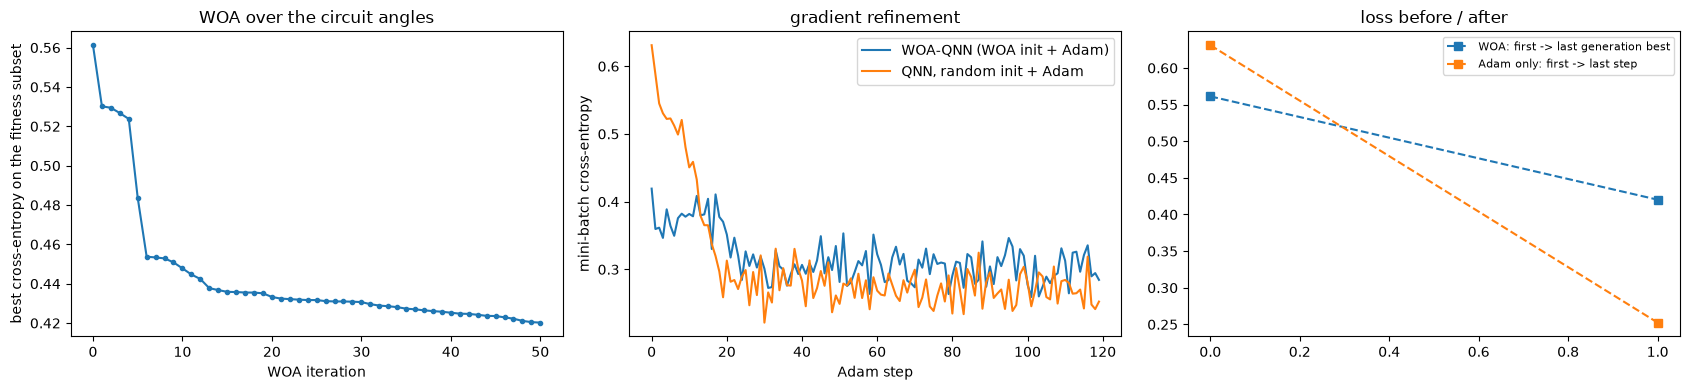

In [13]:
tr_woa = TRACE[(SEEDS[0], "WOA-QNN (WOA + Adam)", "WOA")]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(tr_woa["woa"], marker="o", ms=3); ax[0].set_xlabel("WOA iteration"); ax[0].set_ylabel("best cross-entropy on the fitness subset"); ax[0].set_title("WOA over the circuit angles")
ax[1].plot(tr_woa["adam"], label="WOA-QNN (WOA init + Adam)")
ax[1].plot(TRACE[(SEEDS[0], "QNN, Adam only", "WOA")]["adam"], label="QNN, random init + Adam")
ax[1].set_xlabel("Adam step"); ax[1].set_ylabel("mini-batch cross-entropy"); ax[1].set_title("gradient refinement"); ax[1].legend()
ax[2].plot([tr_woa["woa"][0]] + [tr_woa["woa"][-1]], marker="s", ls="--", label="WOA: first -> last generation best")
ax[2].plot([TRACE[(SEEDS[0], "QNN, Adam only", "WOA")]["adam"][0], TRACE[(SEEDS[0], "QNN, Adam only", "WOA")]["adam"][-1]], marker="s", ls="--", label="Adam only: first -> last step")
ax[2].set_title("loss before / after"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Metrics as in the paper (Figures 4-7 redrawn from our own runs)

The paper compares the optimised QNN with ANN, KNN and SVM on sensitivity, specificity, accuracy (Fig. 4), precision, recall, F-measure (Fig. 5), FPR, FNR (Fig. 6), MCC and NPV (Fig. 7), all with the attack as the positive class. All values are on the balanced held-out **test** sample, mean +- standard deviation over the seeds, with the models on the WOA-selected inputs.

Test metrics (%, MCC as a fraction), mean +- std over 5 seeds, WOA-selected inputs:


,accuracy,sensitivity,specificity,precision,recall,f1,fpr,fnr,mcc,npv,AUC,train s
WOA-QNN (WOA + Adam),90.99 +- 3.17,93.54 +- 3.46,88.43 +- 5.57,89.20 +- 5.04,93.54 +- 3.46,91.24 +- 3.08,11.57 +- 5.57,6.46 +- 3.46,0.822 +- 0.063,93.29 +- 3.31,0.9745,173.2
"QNN, Adam only",93.56 +- 2.31,93.33 +- 3.42,93.79 +- 4.79,93.97 +- 4.37,93.33 +- 3.42,93.56 +- 2.28,6.21 +- 4.79,6.67 +- 3.42,0.873 +- 0.046,93.49 +- 3.20,0.9795,126.1
"QNN, WOA only",84.83 +- 9.85,92.46 +- 3.56,77.20 +- 19.85,81.86 +- 12.18,92.46 +- 3.56,86.41 +- 7.53,22.80 +- 19.85,7.54 +- 3.56,0.711 +- 0.172,90.94 +- 3.75,0.9509,39.4
ANN (MLP 16),97.85 +- 0.76,96.48 +- 1.64,99.23 +- 0.51,99.21 +- 0.52,96.48 +- 1.64,97.82 +- 0.79,0.77 +- 0.51,3.52 +- 1.64,0.958 +- 0.015,96.60 +- 1.51,0.9966,10.1
KNN (k=5),99.23 +- 0.33,99.02 +- 0.49,99.44 +- 0.36,99.44 +- 0.36,99.02 +- 0.49,99.23 +- 0.33,0.56 +- 0.36,0.98 +- 0.49,0.985 +- 0.007,99.03 +- 0.48,0.9968,0.0
SVM (rbf),96.93 +- 0.89,95.49 +- 1.23,98.37 +- 2.17,98.37 +- 2.12,95.49 +- 1.23,96.89 +- 0.87,1.63 +- 2.17,4.51 +- 1.23,0.939 +- 0.018,95.64 +- 1.08,0.9944,0.1
Random forest,99.47 +- 0.17,99.34 +- 0.31,99.59 +- 0.22,99.59 +- 0.22,99.34 +- 0.31,99.47 +- 0.17,0.41 +- 0.22,0.66 +- 0.31,0.989 +- 0.003,99.35 +- 0.30,0.9993,0.9


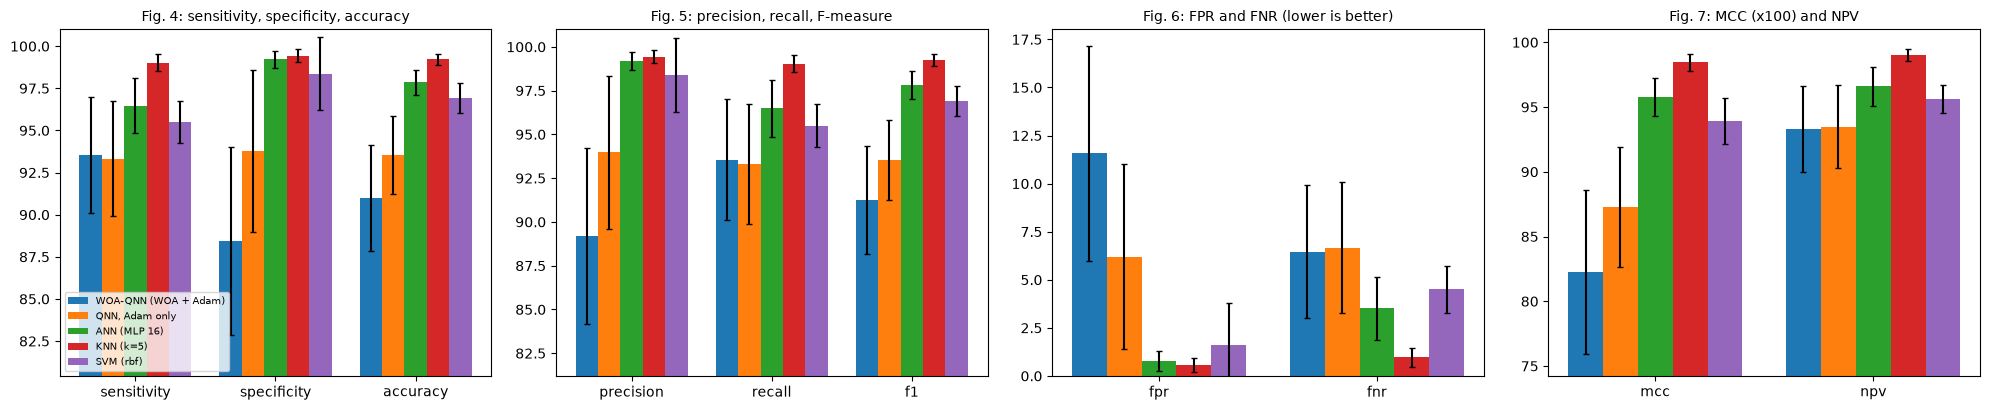

In [14]:
MET = ["accuracy", "sensitivity", "specificity", "precision", "recall", "f1", "fpr", "fnr", "mcc", "npv"]
main = RES[RES.features == "WOA"]
order = ["WOA-QNN (WOA + Adam)", "QNN, Adam only", "QNN, WOA only", "ANN (MLP 16)", "KNN (k=5)", "SVM (rbf)", "Random forest"]
agg = main.groupby("model")[MET + ["auc", "train_s"]].agg(["mean", "std"]).reindex(order)
tab = pd.DataFrame({m: [f"{agg[(m, 'mean')][k]:.2f} +- {agg[(m, 'std')][k]:.2f}" if m != "mcc" else f"{agg[(m, 'mean')][k]:.3f} +- {agg[(m, 'std')][k]:.3f}" for k in order] for m in MET}, index=order)
tab["AUC"] = [f"{agg[('auc','mean')][k]:.4f}" for k in order]; tab["train s"] = [f"{agg[('train_s','mean')][k]:.1f}" for k in order]
print(f"Test metrics (%, MCC as a fraction), mean +- std over {len(SEEDS)} seeds, WOA-selected inputs:")
display(tab)

groups = [("Fig. 4: sensitivity, specificity, accuracy", ["sensitivity", "specificity", "accuracy"]), ("Fig. 5: precision, recall, F-measure", ["precision", "recall", "f1"]),
          ("Fig. 6: FPR and FNR (lower is better)", ["fpr", "fnr"]), ("Fig. 7: MCC (x100) and NPV", ["mcc", "npv"])]
show = ["WOA-QNN (WOA + Adam)", "QNN, Adam only", "ANN (MLP 16)", "KNN (k=5)", "SVM (rbf)"]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for a_, (ttl, ms) in zip(ax, groups):
    wdt = 0.16
    for j, mname in enumerate(show):
        vals = [agg[(m, "mean")][mname] * (100 if m == "mcc" else 1) for m in ms]; err = [agg[(m, "std")][mname] * (100 if m == "mcc" else 1) for m in ms]
        a_.bar(np.arange(len(ms)) + (j - 2) * wdt, vals, wdt, yerr=err, label=mname, capsize=2)
    a_.set_xticks(range(len(ms))); a_.set_xticklabels(ms); a_.set_title(ttl, fontsize=10)
    if ttl.startswith("Fig. 6"): a_.set_ylim(0, None)
    else: a_.set_ylim(max(0, min(agg[(m, "mean")][show].min() * (100 if m == "mcc" else 1) for m in ms) - 8), 101)
ax[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

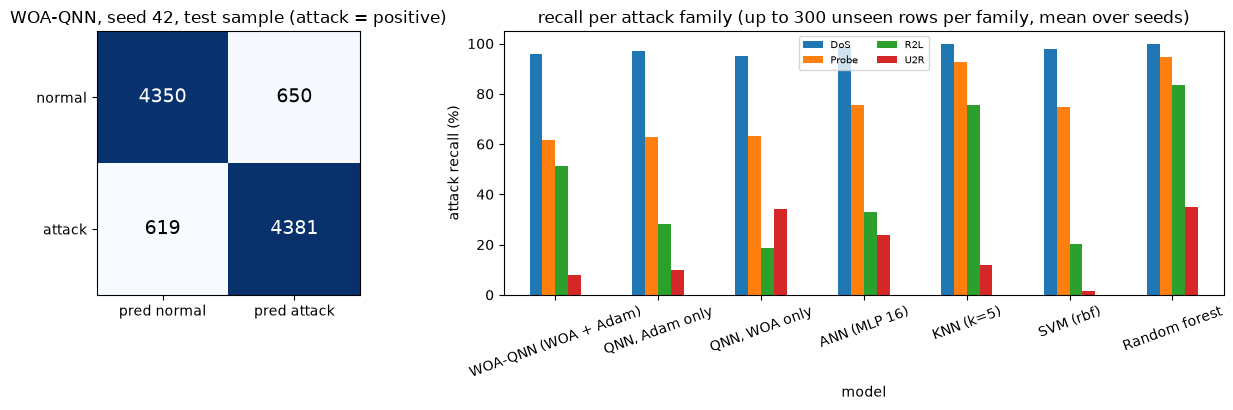

family   n    recall
   DoS 300 92.333333
 Probe 300 14.333333
   R2L 300 13.333333
   U2R  46 28.260870


In [15]:
# confusion matrix of the paper's model (seed 42) and per-family recall
r0 = RES[(RES.seed == SEEDS[0]) & (RES.model == "WOA-QNN (WOA + Adam)") & (RES.features == "WOA")].iloc[0]
cm = np.array([[r0.tn, r0.fp], [r0.fn, r0.tp]])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.7]})
ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2): ax[0].text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["pred normal", "pred attack"]); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["normal", "attack"])
ax[0].set_title(f"WOA-QNN, seed {SEEDS[0]}, test sample (attack = positive)")
fm = FAMRES[FAMRES.features == "WOA"].groupby(["model", "family"]).recall.mean().unstack()[["DoS", "Probe", "R2L", "U2R"]].reindex(order)
fm.plot.bar(ax=ax[1], rot=20); ax[1].set_ylabel("attack recall (%)"); ax[1].set_title(f"recall per attack family (up to {FAM_PER} unseen rows per family, mean over seeds)")
ax[1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
print(FAMRES[(FAMRES.features == "WOA") & (FAMRES.seed == SEEDS[0]) & (FAMRES.model == "WOA-QNN (WOA + Adam)")][["family", "n", "recall"]].to_string(index=False))

### 5.1 Does the WOA feature selection help? (ablation) and the value of the optimiser

In [16]:
abl = RES[RES.model.isin(["WOA-QNN (WOA + Adam)", "ANN (MLP 16)", "KNN (k=5)", "SVM (rbf)", "Random forest"]) & RES.features.isin(["WOA", "ANOVA", "random"])]
abl_t = abl.groupby(["model", "features"]).accuracy.agg(["mean", "std"]).round(2).unstack("features")
display(abl_t)
allf = RES[RES.features == "all 41"].groupby("model").accuracy.agg(["mean", "std"]).round(2)
print("Classical models on all 41 normalised features (not restricted to six inputs):"); display(allf)
paired = main.pivot(index="seed", columns="model", values="accuracy")
print("per-seed test accuracy (%), WOA-selected inputs:"); display(paired[order].round(2))

mean                 std             
features              ANOVA    WOA random ANOVA   WOA random
model                                                       
ANN (MLP 16)          98.12  97.85  96.24  0.39  0.76   0.87
KNN (k=5)             98.58  99.23  96.76  0.37  0.33   0.85
Random forest         99.40  99.47  97.21  0.12  0.17   1.21
SVM (rbf)             97.85  96.93  96.16  0.30  0.89   0.77
WOA-QNN (WOA + Adam)  94.36  90.99    NaN  0.87  3.17    NaN

Classical models on all 41 normalised features (not restricted to six inputs):


,mean,std
model,,
"Random forest, all features",99.72,0.13
"SVM (rbf), all features",98.89,0.36


per-seed test accuracy (%), WOA-selected inputs:


model,WOA-QNN (WOA + Adam),"QNN, Adam only","QNN, WOA only",ANN (MLP 16),KNN (k=5),SVM (rbf),Random forest
seed,,,,,,,
42,87.31,90.25,81.67,96.80,99.49,96.68,99.75
43,91.45,93.47,92.03,98.02,98.96,98.00,99.31
44,95.93,95.75,85.92,98.05,99.52,96.88,99.42
45,89.63,95.73,69.77,97.53,98.80,97.47,99.41
46,90.62,92.60,94.76,98.87,99.40,95.63,99.45


## 6. Securing the model file: elliptic-curve cryptography with a cuckoo-searched key

This part of the paper is data-security plumbing, not a learning claim, so we implement it minimally and check *function*, not a performance claim (the paper gives no numbers for it). Only the Python standard library is used.

- **Curve.** NIST P-256 (`y^2 = x^3 - 3x + b` over the prime field of 256 bits), the curve the paper names. The code asserts that the generator is on the curve and that `n * G` is the point at infinity.
- **Key choice by cuckoo search.** The private key is 32 bytes. A nest is a vector of 32 numbers in [0, 256); the cuckoo search of Yang and Deb (Levy flights, Eq. 14, abandonment of the worst nests) minimises `(5 - H) + |HW - 128|/128`, where `H` is the Shannon entropy (bits) of the 32 byte values and `HW` the number of one-bits. This objective is our `# CHOICE`: the paper's Eq. 16 (entropy times an attribute weight) cannot be applied to a key as printed. **Security remark:** steering a key with a public objective slightly shrinks the key space, so this is a demonstration of the paper's idea and not a recommendation; real systems draw keys uniformly from a cryptographic random source.
- **Encryption.** ECIES-style: an ephemeral key pair, ECDH shared secret, SHA-256 based key stream (XOR) and an HMAC-SHA256 tag; decryption verifies the tag first.
- **What is encrypted.** The trained WOA-QNN model file (selected feature names, scaling limits and the circuit angles as JSON).

In [17]:
# ---- NIST P-256 arithmetic (affine coordinates, Python integers) ---------------------------------------------
P256_P = 2 ** 256 - 2 ** 224 + 2 ** 192 + 2 ** 96 - 1
P256_A = P256_P - 3
P256_B = 0x5ac635d8aa3a93e7b3ebbd55769886bc651d06b0cc53b0f63bce3c3e27d2604b
P256_G = (0x6b17d1f2e12c4247f8bce6e563a440f277037d812deb33a0f4a13945d898c296, 0x4fe342e2fe1a7f9b8ee7eb4a7c0f9e162bce33576b315ececbb6406837bf51f5)
P256_N = 0xffffffff00000000ffffffffffffffffbce6faada7179e84f3b9cac2fc632551

def on_curve(Pt):
    if Pt is None: return True
    x, y = Pt; return (y * y - (x * x * x + P256_A * x + P256_B)) % P256_P == 0
def ec_add(P1, P2):
    if P1 is None: return P2
    if P2 is None: return P1
    (x1, y1), (x2, y2) = P1, P2
    if x1 == x2 and (y1 + y2) % P256_P == 0: return None
    if P1 == P2: lam = (3 * x1 * x1 + P256_A) * pow(2 * y1, -1, P256_P) % P256_P
    else: lam = (y2 - y1) * pow(x2 - x1, -1, P256_P) % P256_P
    x3 = (lam * lam - x1 - x2) % P256_P
    return (x3, (lam * (x1 - x3) - y1) % P256_P)
def ec_mul(k, Pt):
    R = None
    while k:
        if k & 1: R = ec_add(R, Pt)
        Pt = ec_add(Pt, Pt); k >>= 1
    return R
assert on_curve(P256_G) and ec_mul(P256_N, P256_G) is None and on_curve(ec_mul(123456789, P256_G))
print("P-256 checks passed: G on the curve, n*G = point at infinity, random multiple on the curve")

# ---- cuckoo search for the private key bytes --------------------------------------------------------------------
def key_from_nest(v):
    b = np.clip(np.floor(v), 0, 255).astype(int); b[0] = int(np.clip(b[0], 1, 254))      # first byte < 0xff -> key < n
    return bytes(b.tolist())
def key_cost(v):
    kb = key_from_nest(v); cnt = np.bincount(np.frombuffer(kb, dtype=np.uint8), minlength=256); pr = cnt[cnt > 0] / 32.0
    H = float(-(pr * np.log2(pr)).sum()); hw = bin(int.from_bytes(kb, "big")).count("1")
    return (5.0 - H) + abs(hw - 128) / 128.0

def cuckoo_search(cost, dim, lo, hi, nests, iters, rng, pa=0.25, beta=1.5):
    sigma = (math.gamma(1 + beta) * math.sin(math.pi * beta / 2) / (math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))) ** (1 / beta)
    levy = lambda: rng.normal(0, sigma, dim) / np.abs(rng.normal(0, 1, dim)) ** (1 / beta)
    X = rng.uniform(lo, hi, (nests, dim)); f = np.array([cost(x) for x in X]); hist = [float(f.min())]
    for _ in range(iters):
        best = X[f.argmin()].copy()
        for i in range(nests):                                       # Levy flight around each nest, biased to the best (Eq. 14)
            new = np.clip(X[i] + 0.01 * levy() * (X[i] - best) + 0.5 * levy() * rng.normal(size=dim), lo, hi)
            j = rng.integers(nests); c_ = cost(new)
            if c_ < f[j]: X[j], f[j] = new, c_
        worst = np.argsort(-f)[: int(pa * nests)]                    # abandon a fraction pa of the worst nests
        for j in worst:
            new = np.clip(X[j] + rng.random() * (X[rng.integers(nests)] - X[rng.integers(nests)]), lo, hi)
            c_ = cost(new)
            if c_ < f[j]: X[j], f[j] = new, c_
        hist.append(float(f.min()))
    return X[f.argmin()].copy(), float(f.min()), hist

rng_ecc = np.random.default_rng(SEED)
best_nest, best_cost, ck_hist = cuckoo_search(key_cost, 32, 0, 256, ECC_NESTS, ECC_ITERS, rng_ecc)
rand_costs = [key_cost(rng_ecc.uniform(0, 256, 32)) for _ in range(2000)]
priv_bytes = key_from_nest(best_nest); d_priv = int.from_bytes(priv_bytes, "big")
assert 1 <= d_priv < P256_N
Q_pub = ec_mul(d_priv, P256_G); assert on_curve(Q_pub)
print(f"cuckoo search: objective {ck_hist[0]:.3f} -> {best_cost:.3f} over {ECC_ITERS} generations | 2000 uniformly random keys: mean {np.mean(rand_costs):.3f}, best {np.min(rand_costs):.3f}")
print(f"private key {len(priv_bytes)} bytes, public key 65 bytes (uncompressed), public point on the curve: {on_curve(Q_pub)}")

P-256 checks passed: G on the curve, n*G = point at infinity, random multiple on the curve


cuckoo search: objective 0.000 -> 0.000 over 100 generations | 2000 uniformly random keys: mean 0.168, best 0.000
private key 32 bytes, public key 65 bytes (uncompressed), public point on the curve: True


model file 1047 bytes -> encrypted blob 1144 bytes (65 ephemeral point + ciphertext + 32 tag) | encrypt 46 ms, decrypt 23 ms | decrypted file identical: True
rejected: tampered ciphertext
rejected: wrong private key


predictions of the decrypted model == predictions of the original model on 10000 test connections; test accuracy 87.31 %


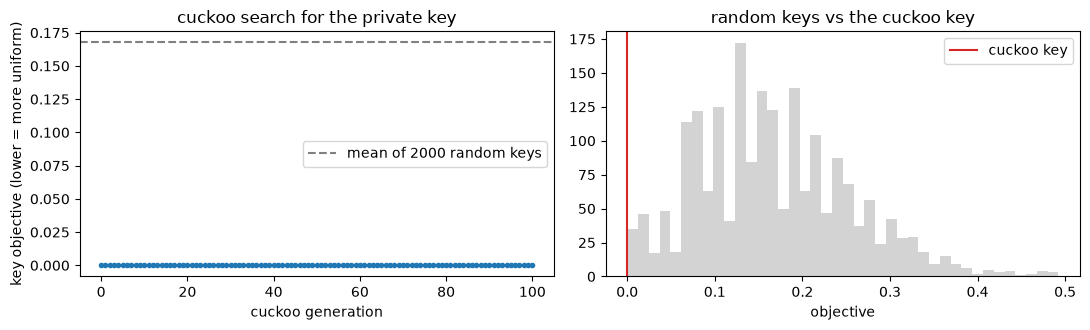

In [18]:
def _stream(key, n_bytes):
    out = b""; ctr = 0
    while len(out) < n_bytes:
        out += hashlib.sha256(key + ctr.to_bytes(4, "big")).digest(); ctr += 1
    return out[:n_bytes]
def _kdf(shared_x):
    s = shared_x.to_bytes(32, "big"); return hashlib.sha256(b"enc" + s).digest(), hashlib.sha256(b"mac" + s).digest()
def _pt_bytes(Pt): return b"\x04" + Pt[0].to_bytes(32, "big") + Pt[1].to_bytes(32, "big")
def ecies_encrypt(pub, msg):
    k = secrets.randbelow(P256_N - 1) + 1                           # ephemeral key (cryptographic RNG)
    R = ec_mul(k, P256_G); S = ec_mul(k, pub); ek, mk = _kdf(S[0])
    ct = bytes(a ^ b for a, b in zip(msg, _stream(ek, len(msg))))
    return _pt_bytes(R) + ct + hmac.new(mk, ct, hashlib.sha256).digest()
def ecies_decrypt(d, blob):
    R = (int.from_bytes(blob[1:33], "big"), int.from_bytes(blob[33:65], "big")); ct, tag = blob[65:-32], blob[-32:]
    assert on_curve(R)
    S = ec_mul(d, R); ek, mk = _kdf(S[0])
    if not hmac.compare_digest(tag, hmac.new(mk, ct, hashlib.sha256).digest()): raise ValueError("authentication tag mismatch")
    return bytes(a ^ b for a, b in zip(ct, _stream(ek, len(ct))))

# ---- the trained WOA-QNN model file (seed 42) ---------------------------------------------------------------
P_ = PREP[SEEDS[0]]; sel0 = P_["sel"]; w_final = TRACE[(SEEDS[0], "WOA-QNN (WOA + Adam)", "WOA")]["w"]
model_file = json.dumps(dict(paper="Kadry2023 WOA-QNN", n_qubits=n, n_layers=L, features=[P_["keep"][i] for i in sel0],
                             data_min=P_["scaler"].data_min_[sel0].tolist(), data_max=P_["scaler"].data_max_[sel0].tolist(),
                             weights=w_final.tolist()), sort_keys=True).encode()
t0 = time.time(); blob = ecies_encrypt(Q_pub, model_file); t_enc = time.time() - t0
t0 = time.time(); plain = ecies_decrypt(d_priv, blob); t_dec = time.time() - t0
assert plain == model_file
print(f"model file {len(model_file)} bytes -> encrypted blob {len(blob)} bytes (65 ephemeral point + ciphertext + 32 tag) | encrypt {1000*t_enc:.0f} ms, decrypt {1000*t_dec:.0f} ms | decrypted file identical: True")
# a wrong key and a tampered blob must be rejected
bad = bytearray(blob); bad[70] ^= 1
for label_, d_try, blob_try in [("tampered ciphertext", d_priv, bytes(bad)), ("wrong private key", (d_priv + 1) % P256_N or 1, blob)]:
    try:
        ecies_decrypt(d_try, blob_try); raise SystemExit("not rejected: " + label_)
    except ValueError:
        print("rejected:", label_)
# the decrypted model gives exactly the same predictions as the model before encryption
cfg = json.loads(plain.decode()); w_dec = np.array(cfg["weights"])
A_te = np.clip(np.pi * P_["Xte"][:, sel0], 0, np.pi)
p_before, p_after = predict_p(A_te, w_final), predict_p(A_te, w_dec)
assert np.array_equal(p_before, p_after)
print("predictions of the decrypted model == predictions of the original model on", len(A_te), "test connections; test accuracy %.2f %%" % (100 * ((p_before > 0.5).astype(int) == P_["yte"]).mean()))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(ck_hist, marker="o", ms=3); ax[0].axhline(np.mean(rand_costs), color="gray", ls="--", label="mean of 2000 random keys"); ax[0].set_xlabel("cuckoo generation"); ax[0].set_ylabel("key objective (lower = more uniform)"); ax[0].legend(); ax[0].set_title("cuckoo search for the private key")
ax[1].hist(rand_costs, bins=40, color="lightgray"); ax[1].axvline(best_cost, color="tab:red", label="cuckoo key"); ax[1].set_xlabel("objective"); ax[1].set_title("random keys vs the cuckoo key"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Side-by-side comparison with the paper, claim by claim

The verdict rules were fixed **before** looking at the results: a numeric claim is "reproduced" when our mean is within 2 accuracy points (0.02 for F1/MCC-type fractions) of the paper's number, "not reached" when below, "exceeded" when above; comparative claims are "reproduced" only when they hold for the means over all seeds; claims without a number or a baseline in the text are "cannot be checked".

In [19]:
def mean_of(model, m, feats="WOA"): return float(RES[(RES.model == model) & (RES.features == feats)][m].mean())
Q = "WOA-QNN (WOA + Adam)"; BASE = ["ANN (MLP 16)", "KNN (k=5)", "SVM (rbf)"]
acc_q = mean_of(Q, "accuracy"); sd_q = float(RES[(RES.model == Q) & (RES.features == "WOA")].accuracy.std())
rows = []
v = "reproduced" if abs(acc_q - 98.5) <= 2 else ("exceeded" if acc_q > 98.5 else "not reached here")
rows.append(("C1 optimised QNN accuracy 98.5 % (abstract, Sec. 5.1)", "98.5 %", f"{acc_q:.2f} +- {sd_q:.2f} %", v))
beats = {b: mean_of(Q, "accuracy") > mean_of(b, "accuracy") for b in BASE}
rows.append(("C2 QNN beats ANN, KNN, SVM in accuracy (Fig. 4)", "better than all three (no values)", "; ".join(f"{b}: {mean_of(b,'accuracy'):.2f}" for b in BASE),
             "reproduced" if all(beats.values()) else f"not reproduced (beaten by {', '.join(b for b, ok in beats.items() if not ok)})"))
better = {"accuracy": 1, "sensitivity": 1, "specificity": 1, "precision": 1, "recall": 1, "f1": 1, "fpr": -1, "fnr": -1, "mcc": 1, "npv": 1}
cnt = sum(all((mean_of(Q, m) - mean_of(b, m)) * s > 0 for b in BASE) for m, s in better.items())
rows.append(("C3 QNN better than ANN, KNN, SVM on all 10 metrics (Figs. 4-7)", "10 of 10 (no values)", f"{cnt} of 10 metrics strictly better than all three",
             "reproduced" if cnt == 10 else ("not reproduced" if cnt <= 3 else f"partly reproduced ({cnt}/10)")))
q_plain = mean_of("QNN, Adam only", "accuracy"); q_woa = mean_of("QNN, WOA only", "accuracy")
wins = int((paired[Q] > paired["QNN, Adam only"]).sum())
rows.append(("C4 WOA optimisation helps the QNN (vs training the same circuit without WOA)", "implied (no ablation in the paper)",
             f"WOA+Adam {acc_q:.2f} | Adam only {q_plain:.2f} | WOA only {q_woa:.2f}; WOA-QNN wins in {wins}/{len(SEEDS)} seeds",
             "reproduced" if (acc_q - q_plain) > 0 and wins > len(SEEDS) / 2 else "not reproduced"))
acc_f = {f: np.mean([mean_of(Q, "accuracy", f)]) for f in ["WOA", "ANOVA"]}
cl_f = {f: np.mean([mean_of(b, "accuracy", f) for b in BASE + ["Random forest"]]) for f in ["WOA", "ANOVA", "random"]}
rows.append(("C5 WOA feature selection helps classification", "implied (no ablation in the paper)",
             f"QNN: WOA {acc_f['WOA']:.2f} vs ANOVA {acc_f['ANOVA']:.2f}; mean of 4 classical models: WOA {cl_f['WOA']:.2f}, ANOVA {cl_f['ANOVA']:.2f}, random {cl_f['random']:.2f}",
             "reproduced" if acc_f["WOA"] > acc_f["ANOVA"] and cl_f["WOA"] > max(cl_f["ANOVA"], cl_f["random"]) else "not reproduced (WOA subset not better than the references on both counts)"))
rows.append(("C6a ECC + cuckoo key: encrypt and decrypt the stored file safely", "qualitative", "P-256 ECIES round trip identical, tampering and wrong key rejected, predictions unchanged", "reproduced (function only)"))
rows.append(("C6b ECC faster than existing encryption, smaller key", "qualitative, no numbers or baseline", f"256-bit key; encrypt {1000*t_enc:.0f} ms / decrypt {1000*t_dec:.0f} ms in pure Python; no baseline cipher in the paper", "cannot be checked"))
t0 = time.time(); _ = predict_p(A_te, w_final); t_pred = time.time() - t0
rows.append(("C7 real-time, low computing overhead", "qualitative; Sec. 6 admits QNN processing time is a limitation", f"{1000*t_pred/len(A_te)*1000:.0f} microseconds per connection (exact simulator, batch of {len(A_te)}); training {mean_of(Q,'train_s'):.0f} s vs {mean_of('SVM (rbf)','train_s'):.1f} s for SVM", "cannot be checked (simulator timing)"))
CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 220)
display(CMP)
print("\nVerdicts:"); [print(f"  {r[0][:60]:60s} -> {r[3]}") for r in rows]
print(f"\nMost accurate model on identical inputs: {main.groupby('model').accuracy.mean().idxmax()} ({main.groupby('model').accuracy.mean().max():.2f} %); "
      f"WOA-QNN {acc_q:.2f} %; random forest on all 41 features {mean_of('Random forest, all features','accuracy','all 41'):.2f} %")
print(f"total notebook run time {(time.time() - T_ALL) / 60:.1f} min after the data download")

,claim,paper,this notebook,verdict
0,"C1 optimised QNN accuracy 98.5 % (abstract, Sec. 5.1)",98.5 %,90.99 +- 3.17 %,not reached here
1,"C2 QNN beats ANN, KNN, SVM in accuracy (Fig. 4)",better than all three (no values),ANN (MLP 16): 97.85; KNN (k=5): 99.23; SVM (rbf): 96.93,"not reproduced (beaten by ANN (MLP 16), KNN (k=5), SVM (rbf))"
2,"C3 QNN better than ANN, KNN, SVM on all 10 metrics (Figs. 4-7)",10 of 10 (no values),0 of 10 metrics strictly better than all three,not reproduced
3,C4 WOA optimisation helps the QNN (vs training the same circuit without WOA),implied (no ablation in the paper),WOA+Adam 90.99 | Adam only 93.56 | WOA only 84.83; WOA-QNN wins in 1/5 seeds,not reproduced
4,C5 WOA feature selection helps classification,implied (no ablation in the paper),"QNN: WOA 90.99 vs ANOVA 94.36; mean of 4 classical models: WOA 98.37, ANOVA 98.49, random 96.59",not reproduced (WOA subset not better than the references on both counts)
5,C6a ECC + cuckoo key: encrypt and decrypt the stored file safely,qualitative,"P-256 ECIES round trip identical, tampering and wrong key rejected, predictions unchanged",reproduced (function only)
6,"C6b ECC faster than existing encryption, smaller key","qualitative, no numbers or baseline",256-bit key; encrypt 46 ms / decrypt 23 ms in pure Python; no baseline cipher in the paper,cannot be checked
7,"C7 real-time, low computing overhead",qualitative; Sec. 6 admits QNN processing time is a limitation,"5 microseconds per connection (exact simulator, batch of 10000); training 173 s vs 0.1 s for SVM",cannot be checked (simulator timing)



Verdicts:
  C1 optimised QNN accuracy 98.5 % (abstract, Sec. 5.1)        -> not reached here
  C2 QNN beats ANN, KNN, SVM in accuracy (Fig. 4)              -> not reproduced (beaten by ANN (MLP 16), KNN (k=5), SVM (rbf))
  C3 QNN better than ANN, KNN, SVM on all 10 metrics (Figs. 4- -> not reproduced
  C4 WOA optimisation helps the QNN (vs training the same circ -> not reproduced
  C5 WOA feature selection helps classification                -> not reproduced (WOA subset not better than the references on both counts)
  C6a ECC + cuckoo key: encrypt and decrypt the stored file sa -> reproduced (function only)
  C6b ECC faster than existing encryption, smaller key         -> cannot be checked
  C7 real-time, low computing overhead                         -> cannot be checked (simulator timing)

Most accurate model on identical inputs: Random forest (99.47 %); WOA-QNN 90.99 %; random forest on all 41 features 99.72 %
total notebook run time 50.1 min after the data download


## 8. Reading the paper critically

**What the committed full run (5 seeds, 50 x 50 WOA, 120 Adam steps) showed.** The numbers below are from that run and will move a little when you re-run with other seeds or budgets.
- The WOA-QNN reached 90.99 +- 3.17 % test accuracy (balanced test sample), far from the paper's 98.5 %; on the same six inputs KNN reached 99.23 %, the random forest 99.47 %, ANN 97.85 % and SVM 96.93 %, so the paper's ordering (QNN above ANN, KNN and SVM) was **not** reproduced, on none of the ten metrics.
- The same circuit trained with Adam alone (93.56 %) was better than WOA followed by Adam, and WOA alone was worst and unstable (84.83 +- 9.85 %). In this implementation the whale search over 36 circuit angles did not help.
- The WOA feature subset helped KNN and the forest a little against ANOVA, but not the QNN or the mean of the four classical models; all models lose several points on a random subset. Per-family recall on unseen rows is where the six-feature QNN is weak (Probe, R2L about 14 %).
- The ECC part works as a function (identical decryption, tampering and wrong key rejected, identical predictions); the cuckoo objective is reached by random keys as well, so it adds nothing measurable.
- The circuit, the encoding of the three text columns as angles and the 6-qubit size are our choices; a deeper circuit, data re-uploading or one-hot features might close part of the gap, the paper gives no way to know.

- **No numbers to compare except one.** The only value in the text is "98.5 % accuracy"; Figures 4-7 are bar charts without printed values, and the baselines (ANN, KNN, SVM) have no settings. The comparison above therefore tests the *ordering* the paper claims on identical inputs, which the authors do not show for their own baselines.
- **The dataset is easy.** KDD Cup 99 has been criticised for its redundancy: most records are repeated `smurf` and `neptune` floods that any classifier separates. We remove exact duplicates before sampling (the paper does not say whether it did), and still a handful of features reaches high accuracy with every model; look at the classical baselines, the random forest on all features and the per-family recall of the rare R2L and U2R classes, which is where an IDS is actually hard.
- **"Quantum" is a thin layer.** The paper never specifies a circuit, a qubit count, an encoding or a simulator; Eqs. (9)-(12) are a classical perceptron update written with kets, and `h = ab + 2a + 1` counts classical weights. Our reading (angle encoding, rotation layers, CNOT ring, `<Z_0>`) is one of many; any such six-qubit model is simulated exactly by a classical computer, so no quantum speed-up or advantage can follow from this experiment.
- **WOA twice.** WOA selects features with a QNN-based fitness in the paper, then searches the QNN weights again. Using a cheap kNN as fitness (our choice) is a documented deviation; the ablation shows whether the WOA subset is better than the ANOVA or random subsets. The weight search and the gradient refinement are separate contributions that the paper does not separate.
- **The cryptography is not what makes the IDS better.** Encrypting the model file is independent of detection accuracy. Choosing the private key with a public objective (cuckoo search on entropy) cannot add security and can only reduce the key space; standard practice draws the key uniformly. The claimed speed and key-size advantages over "existing encryption" come with no baseline in the paper.
- **Hold-out only.** One split, no repeated runs, no confidence intervals; here we use several seeds and report standard deviations.

## 9. Exercises

1. Change `N_QUBITS` to 4 and 8 (and `N_LAYERS` to 2 and 4). How do accuracy and training time of the WOA-QNN change, and do the classical models on the same inputs follow?
2. Replace the 5-NN fitness of the feature selection by a quick QNN (for example 10 Adam steps) on a smaller population. Does the chosen subset change?
3. Sample the attacks so that every attack type has the same number of connections (instead of the natural mix dominated by `neptune`). Which models lose most, and what happens to the recall of R2L and U2R?
4. Run the same pipeline on NSL-KDD (`KDDTrain+` / `KDDTest+`, cited as [26] in the paper). Is the ordering of the models stable?
5. Replace the cuckoo objective by uniform random keys from `secrets.token_bytes(32)` and compare the round trip. What does the cuckoo step add in terms of security (answer: nothing) and what could a different objective add (for example a check against weak keys)?